# Can a Risk Matrix Hide a Red Flag?

***Course project – Math Concepts for Developers***

***Author: Yana Stoyanova***

## Contents
1. Introduction
2. The Risk Matrix Model
3. A Simple Example: Can a Single Red Flag Change the Final Rating?
4. Synthetic Customer Data
5. Results
6. Experiment: different weights and an extra rule
7. Conclusion
8. References

## 1. Introduction

Banks and payment companies must assess the money-laundering risk associated with each customer. This is known as the **risk-based approach** and forms a key principle of international and European anti-money-laundering frameworks. Customers assessed as higher risk are subject to enhanced monitoring and additional controls, while lower-risk customers generally require fewer checks.

A common tool used for this purpose is a **risk matrix**. Customers are evaluated across several risk factors, such as geography, customer type, industry, products and services, or distribution channels. Each factor receives a rating of Low, Medium, or High, which can be represented numerically as 1, 2, and 3. These ratings are then combined using a **weighted average** to produce an overall risk score and classification.

A potential limitation of this approach is that a high-risk rating on one factor can be offset by low-risk ratings on other factors. As a result, a customer with a significant warning sign, referred to in this project as a **red flag**, may still receive an overall Low-risk classification.

**Research question**: How often does a customer with at least one High-risk factor receive an overall Low-risk rating, and can a simple additional rule reduce this problem?

**Project objectives**:

- define a simple risk matrix with five risk factors (Section 2);
- analyse mathematically when a single red flag can affect the overall rating (Section 3);
- generate a synthetic population of 1,000 customers (Section 4);
- measure how often red flags are hidden by the risk-scoring model (Section 5);
- evaluate alternative weights and an additional red-flag rule (Section 6).

All customer data used in this project is synthetic and generated randomly. No real customer information is used.

## 2. The risk matrix model

### 2.1 Risk factors

I use five risk factors, based on the types of factors described in public guidance (EBA Guidelines on ML/TF risk factors):

| Factor | What it means | Example of High risk |
|---|---|---|
| Geography | Countries the customer is connected to | A country on a FATF high-risk list |
| Customer type | Who the customer is and how it is owned | A company with a complex ownership structure |
| Industry | What business the customer does | A cash-intensive business |
| Product | Which products the customer uses | Large cross-border payments |
| Channel | How the customer was onboarded | Fully online with weak identity checks |

Each factor gets a rating: **Low = 1, Medium = 2, High = 3.**

### 2.2 Weights

Not all factors are equally important, so each factor gets a weight $w_i$. The weights are my own choice, and they must add up to 1:

| Factor | Weight |
|---|---|
| Geography | 0.30 |
| Customer type | 0.25 |
| Industry | 0.20 |
| Product | 0.15 |
| Channel | 0.10 |

### 2.3 Risk score

The risk score is the **weighted average** of the ratings:

$$S = w_1 x_1 + w_2 x_2 + w_3 x_3 + w_4 x_4 + w_5 x_5$$

where $x_i$ is the rating (1, 2 or 3) on factor $i$. Because the weights add up to 1, the score is always between 1 (all factors Low) and 3 (all factors High).

**Example.** A customer rated High on geography, Medium on industry and Low on everything else:

$$S = 0.30 \cdot 3 + 0.25 \cdot 1 + 0.20 \cdot 2 + 0.15 \cdot 1 + 0.10 \cdot 1 = 0.90 + 0.25 + 0.40 + 0.15 + 0.10 = 1.80$$

### 2.4 Risk levels

I split the range from 1 to 3 into three equal parts:

| Score | Risk level |
|---|---|
| below 1.67 (= 5/3) | Low |
| from 1.67 to below 2.33 (= 7/3) | Medium |
| 2.33 or more | High |

So the example customer above (score 1.80) is **Medium**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from risk_model import (
    FACTORS, LOW_THRESHOLD, HIGH_THRESHOLD,
    generate_customers, risk_score, risk_level, has_red_flag, apply_red_flag_rule,
)

WEIGHTS = {
    "geography": 0.30,
    "customer_type": 0.25,
    "industry": 0.20,
    "product": 0.15,
    "channel": 0.10,
}

# Check the example from Section 2.3
example = pd.DataFrame([{"geography": 3, "customer_type": 1, "industry": 2, "product": 1, "channel": 1}])
example_score = risk_score(example, WEIGHTS)
print("Example score:", round(example_score[0], 2))
print("Example risk level:", risk_level(example_score)[0])

Example score: 1.8
Example risk level: Medium


## 3. A small calculation: can one red flag change the rating?

Take a customer who is **High on one factor** (factor $i$) and **Low on all other factors**. Their score is:

$$S = 3 \cdot w_i + 1 \cdot (1 - w_i) = 1 + 2 w_i$$

(The other weights add up to $1 - w_i$, and all those factors have rating 1.)

**When is this customer at least Medium?** We need $S \ge 5/3$:

$$1 + 2 w_i \ge \frac{5}{3} \quad\Longrightarrow\quad 2 w_i \ge \frac{2}{3} \quad\Longrightarrow\quad w_i \ge \frac{1}{3}$$

**When is this customer High?** We need $S \ge 7/3$:

$$1 + 2 w_i \ge \frac{7}{3} \quad\Longrightarrow\quad w_i \ge \frac{2}{3}$$

**What this means.** In my model, the biggest weight is 0.30, which is less than 1/3. So a customer with **one** High factor and everything else Low is **always rated Low**, no matter which factor is High. Even a customer linked to a high-risk country gets a Low rating if everything else about them is low risk.

Let me check this with the code:

In [2]:
rows = []
for factor in FACTORS:
    customer = {f: 1 for f in FACTORS}   # all factors Low
    customer[factor] = 3                 # one factor High
    rows.append(customer)

one_red_flag = pd.DataFrame(rows, index=["High on " + f for f in FACTORS])
one_red_flag["score"] = risk_score(one_red_flag, WEIGHTS).round(2)
one_red_flag["risk level"] = risk_level(one_red_flag["score"])
one_red_flag

,geography,customer_type,industry,product,channel,score,risk level
High on geography,3,1,1,1,1,1.6,Low
High on customer_type,1,3,1,1,1,1.5,Low
High on industry,1,1,3,1,1,1.4,Low
High on product,1,1,1,3,1,1.3,Low
High on channel,1,1,1,1,3,1.2,Low


The table confirms the calculation: every customer with only one red flag gets a score of $1 + 2w_i$, and all of them are rated **Low**.

But how often does this happen with "real-looking" customers, who often have a mix of Low, Medium and High ratings? To answer this, I need data.

## 4. Data

I don't use real customer data. Instead, I create **1,000 random customers**. For every factor, each customer gets Low, Medium or High with these probabilities (my own assumptions: most customers are low risk):

| Factor | P(Low) | P(Medium) | P(High) |
|---|---|---|---|
| Geography | 0.70 | 0.20 | 0.10 |
| Customer type | 0.60 | 0.30 | 0.10 |
| Industry | 0.60 | 0.30 | 0.10 |
| Product | 0.50 | 0.40 | 0.10 |
| Channel | 0.50 | 0.40 | 0.10 |

Each factor is drawn independently, with a fixed random seed so the results are the same every time the notebook is run.

In [3]:
PROBABILITIES = {
    "geography":     [0.70, 0.20, 0.10],
    "customer_type": [0.60, 0.30, 0.10],
    "industry":      [0.60, 0.30, 0.10],
    "product":       [0.50, 0.40, 0.10],
    "channel":       [0.50, 0.40, 0.10],
}

customers = generate_customers(1000, PROBABILITIES, seed=42)
customers.head()

,geography,customer_type,industry,product,channel
0,2,1,2,2,2
1,1,1,1,2,1
2,2,1,3,1,2
3,1,1,2,2,1
4,1,2,1,1,2


Quick check that the generated data looks as expected. The share of each rating should be close to the probabilities above:

In [4]:
shares = pd.DataFrame({f: customers[f].value_counts(normalize=True).sort_index() for f in FACTORS}).T
shares.columns = ["Low (1)", "Medium (2)", "High (3)"]
shares.round(2)

,Low (1),Medium (2),High (3)
geography,0.70,0.21,0.10
customer_type,0.59,0.30,0.11
industry,0.62,0.28,0.10
product,0.51,0.39,0.10
channel,0.52,0.39,0.08


The shares are close to the chosen probabilities, so the data was generated correctly.

## 5. Results

### 5.1 Scores and risk levels

First I calculate the score and risk level for every customer.

risk_level
Low       730
Medium    259
High       11
Name: count, dtype: int64


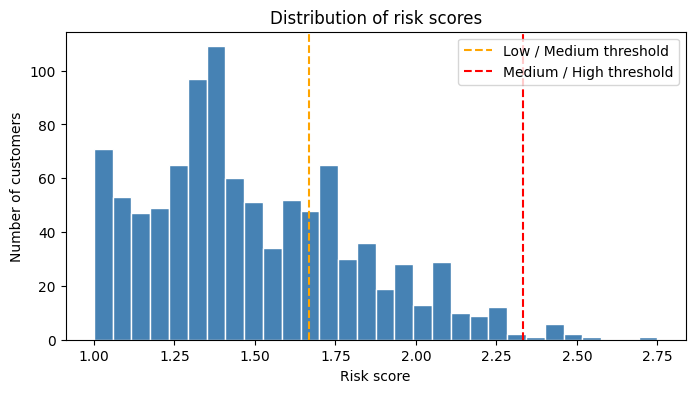

In [5]:
customers["score"] = risk_score(customers, WEIGHTS)
customers["risk_level"] = risk_level(customers["score"])
customers["red_flag"] = has_red_flag(customers)

print(customers["risk_level"].value_counts().reindex(["Low", "Medium", "High"]))

plt.figure(figsize=(8, 4))
plt.hist(customers["score"], bins=30, color="steelblue", edgecolor="white")
plt.axvline(LOW_THRESHOLD, color="orange", linestyle="--", label="Low / Medium threshold")
plt.axvline(HIGH_THRESHOLD, color="red", linestyle="--", label="Medium / High threshold")
plt.xlabel("Risk score")
plt.ylabel("Number of customers")
plt.title("Distribution of risk scores")
plt.legend()
plt.show()

Most customers have a low score, which matches the assumption that most customers are low risk.

### 5.2 How many red flags are hidden?

Now the main question. A customer has a **red flag** if at least one factor is High. I count how many of these customers still get an overall **Low** rating:

$$\text{hidden red flags} = \frac{\text{customers with a red flag and rated Low}}{\text{all customers with a red flag}}$$

In [6]:
red_flag_customers = customers[customers["red_flag"]]
hidden = red_flag_customers[red_flag_customers["risk_level"] == "Low"]

print("Customers with at least one red flag:", len(red_flag_customers))
print("... of them rated Low:", len(hidden))
print(f"Hidden red flags: {len(hidden) / len(red_flag_customers):.1%}")

Customers with at least one red flag: 398
... of them rated Low: 164
Hidden red flags: 41.2%


Which red flags are hidden most often? For each factor, I look at the customers who are High on that factor and check what share of them is still rated Low:

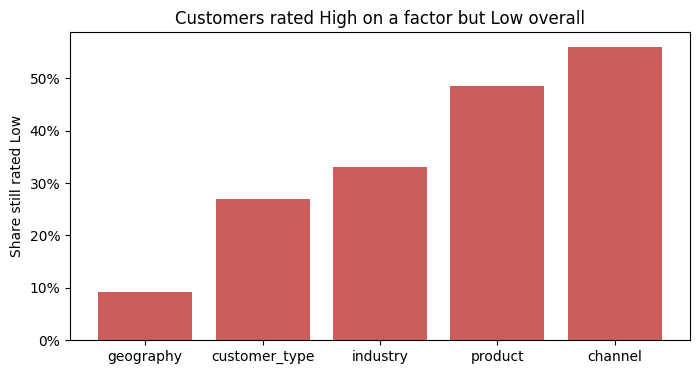

geography         9%
customer_type    27%
industry         33%
product          49%
channel          56%
dtype: str

In [7]:
hidden_by_factor = {}
for factor in FACTORS:
    high_on_factor = customers[customers[factor] == 3]
    hidden_by_factor[factor] = (high_on_factor["risk_level"] == "Low").mean()

hidden_by_factor = pd.Series(hidden_by_factor)

plt.figure(figsize=(8, 4))
plt.bar(hidden_by_factor.index, hidden_by_factor.values, color="indianred")
plt.ylabel("Share still rated Low")
plt.title("Customers rated High on a factor but Low overall")
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.show()

hidden_by_factor.map("{:.0%}".format)

**What I see:** a large share of customers with a red flag are rated Low. The effect is strongest for the factors with small weights (product and channel): a High rating there changes the score very little. Even for geography, the factor with the biggest weight, about one in ten High-risk customers stays Low.

This matches the calculation in Section 3: with these weights, one red flag alone is never enough, so a customer with a red flag only moves up if they also have Medium or High ratings on other factors.

## 6. Experiment: different weights and an extra rule

### 6.1 Does the problem come from my choice of weights?

Maybe the problem only appears because of the weights I chose. I test **equal weights** (0.2 for every factor). From Section 3, a single red flag needs a weight of at least 1/3, and 0.2 is also less than 1/3, so I expect the problem to stay.

In [8]:
EQUAL_WEIGHTS = {f: 0.2 for f in FACTORS}

levels_equal = risk_level(risk_score(customers, EQUAL_WEIGHTS))
hidden_equal = (levels_equal[customers["red_flag"]] == "Low").mean()

hidden_mine = (customers.loc[customers["red_flag"], "risk_level"] == "Low").mean()
print(f"Hidden red flags with my weights:    {hidden_mine:.1%}")
print(f"Hidden red flags with equal weights: {hidden_equal:.1%}")

Hidden red flags with my weights:    41.2%
Hidden red flags with equal weights: 42.2%


The problem stays with equal weights too. It is not caused by one specific choice of weights: it comes from the **weighted average itself**, which lets low ratings balance out a high one.

### 6.2 An extra rule

A simple fix is to add one rule on top of the score:

> **Red-flag rule:** if a customer is High on at least one factor, their overall risk level is at least Medium.

This rule only moves customers **up** (from Low to Medium). It never lowers anyone's rating. I compare three approaches:

1. **Weighted average** (the original model)
2. **Weighted average + red-flag rule**
3. **Highest rating**: the overall level is simply the customer's highest factor rating. This is the strictest possible approach.

For each approach I look at two things:
- **hidden red flags**: the share of red-flag customers rated Low (lower is better),
- **customers needing extra checks**: the share of *all* customers rated Medium or High. This shows the workload for the compliance team (lower is better).

In [9]:
levels_rule = apply_red_flag_rule(customers["risk_level"], customers)

highest = customers[FACTORS].max(axis=1)
levels_highest = highest.map({1: "Low", 2: "Medium", 3: "High"})

approaches = {
    "Weighted average": customers["risk_level"],
    "Weighted average + red-flag rule": pd.Series(levels_rule, index=customers.index),
    "Highest rating": levels_highest,
}

summary = {}
for name, levels in approaches.items():
    levels = pd.Series(levels).astype(str)
    summary[name] = {
        "hidden red flags": (levels[customers["red_flag"]] == "Low").mean(),
        "customers needing extra checks": (levels != "Low").mean(),
    }

summary = pd.DataFrame(summary).T
summary.map("{:.1%}".format)

,hidden red flags,customers needing extra checks
Weighted average,41.2%,27.0%
Weighted average + red-flag rule,0.0%,43.4%
Highest rating,0.0%,92.9%


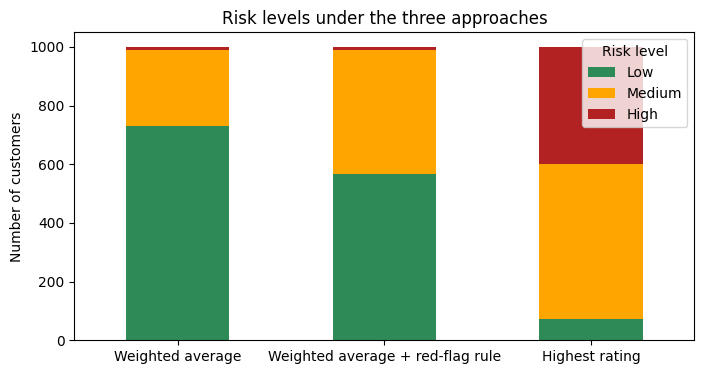

In [10]:
counts = pd.DataFrame({
    name: pd.Series(levels).astype(str).value_counts().reindex(["Low", "Medium", "High"], fill_value=0)
    for name, levels in approaches.items()
}).T

counts.plot(kind="bar", stacked=True, figsize=(8, 4), color=["seagreen", "orange", "firebrick"], rot=0)
plt.ylabel("Number of customers")
plt.title("Risk levels under the three approaches")
plt.legend(title="Risk level")
plt.show()

**What I see:**

- The **weighted average** has the lowest workload, but it hides many red flags.
- The **highest rating** approach hides no red flags, but it sends most customers to extra checks, which would be too much work in practice.
- The **red-flag rule** hides no red flags and needs much less work than the "highest rating" approach. The number of High-risk customers does not change; only some Low customers move to Medium.

So the red-flag rule is a good compromise between missing red flags and creating too much work.

## 7. Conclusion

**Answer to the question.** Yes, a risk matrix based on a weighted average can hide red flags. With the weights in this project, a customer with only one High factor is always rated Low (Section 3), and in the random data a large share of all red-flag customers ended up rated Low (Section 5). Changing to equal weights did not fix this (Section 6.1), because the problem comes from the weighted average itself.

**A simple fix.** Adding the rule "at least one High factor means at least Medium" removed all hidden red flags, while keeping the workload much lower than the strictest approach (Section 6.2).

**What I learned.** A simple formula like a weighted average can have effects that are not obvious at first. A small calculation (Section 3) was enough to predict the result before looking at any data, and the data then showed how big the effect is.

**Limitations:**
- The data is random and the probabilities, weights and thresholds are my own assumptions. Real customers would look different.
- The factors are generated independently, but in reality they are often connected (for example, a risky industry and a risky country often go together).
- The ratings 1, 2, 3 are just labels for Low, Medium, High. Other numbers (for example 1, 2, 5) would give different scores.
- Whether every red flag *should* lead to at least Medium is a business decision, not a mathematical fact.

**Next steps:**
- Try different thresholds and see how many customers change level.
- Make some factors depend on each other in the random data.
- Test other number codings for Low, Medium and High.

## 8. References

1. FATF (2012, updated). *International Standards on Combating Money Laundering and the Financing of Terrorism & Proliferation – The FATF Recommendations*, Recommendation 1 (Assessing risks and applying a risk-based approach). https://www.fatf-gafi.org
2. European Banking Authority (2021). *Guidelines on customer due diligence and the factors credit and financial institutions should consider when assessing the money laundering and terrorist financing risk (The ML/TF Risk Factors Guidelines)*, EBA/GL/2021/02. https://www.eba.europa.eu
3. Cox, L. A. Jr. (2008). What's Wrong with Risk Matrices? *Risk Analysis*, 28(2), 497–512.
4. Harris, C. R. et al. (2020). Array programming with NumPy. *Nature*, 585, 357–362.
5. McKinney, W. (2010). Data Structures for Statistical Computing in Python. *Proceedings of the 9th Python in Science Conference*, 56–61.
6. Hunter, J. D. (2007). Matplotlib: A 2D Graphics Environment. *Computing in Science & Engineering*, 9(3), 90–95.

---

*This project was made with the help of an AI assistant (Claude, by Anthropic).*